<a href="https://colab.research.google.com/github/Threebelt903744/tess-transit-hunter/blob/main/notebooks/01_single_star_bls.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Single-Star BLS Transit Detection
## Target 1: Pi Mensae c (TIC 261136679)

In [5]:
pip install -q lightkurve

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

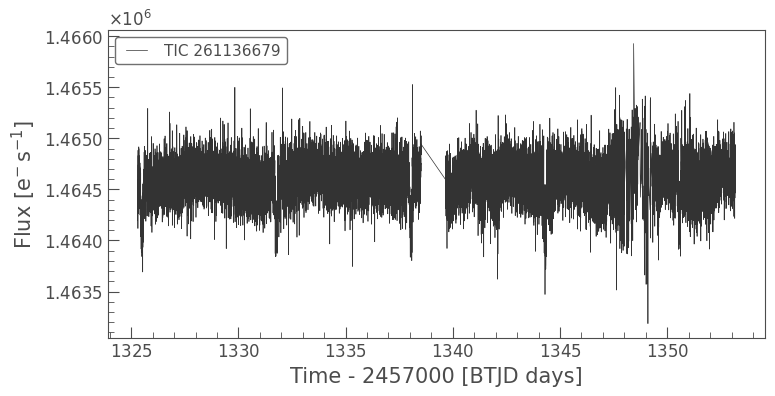

In [3]:
import os
import lightkurve as lk

# 1. Create a local data/ folder in the current Colab runtime
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

# 2. Search for a TESS target (example: TIC 261136679 / Pi Mensae)
search_result = lk.search_lightcurve("TIC 261136679", mission="TESS")

# 3. Download the first light curve directly into data/
lc = search_result[0].download(download_dir=DATA_DIR)

# 4. Plot to confirm it loaded properly
lc.plot()

Detected period: 6.2701 d | Transit time: 1325.4970


(-0.3, 0.3)

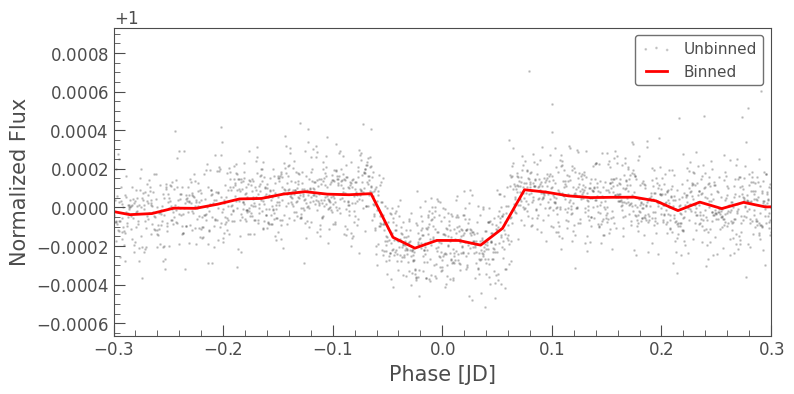

In [4]:
import numpy as np

# 1. Remove NaNs, clip extreme outliers, and flatten slow trends
clean_lc = lc.remove_nans().remove_outliers(sigma=5).flatten(window_length=401)

# 2. Search for periodic transit signals using Box Least Squares (BLS)
period_grid = np.linspace(1, 15, 10000)
bls = clean_lc.to_periodogram(method="bls", period=period_grid, frequency_factor=500)

best_period = bls.period_at_max_power
best_t0 = bls.transit_time_at_max_power
print(f"Detected period: {best_period:.4f} | Transit time: {best_t0.value:.4f}")

# 3. Fold the light curve at the detected period and bin it to reduce noise
folded_lc = clean_lc.fold(period=best_period, epoch_time=best_t0)
ax = folded_lc.scatter(alpha=0.2, label="Unbinned")
folded_lc.bin(time_bin_size=0.02).plot(ax=ax, color="red", lw=2, label="Binned")
ax.set_xlim(-0.3, 0.3)